# 04 · The deployed method at 100 m

**Question:** how well does the land-use forecast score as the platform's backend runs it (`main`, commit 6710b3d), and does the method in the methodology document (`Docs/Methodology_LandUse_Guinea.docx`) score better?

Both are run with the platform's own code (a read-only copy of `landuse_tool`) on the three windows of the README: backtest 2021→2022→2023, validation 2022→2023→2024, test 2023→2024→2025. The backend runs with three seeds; the growth-mode option and the document's method run with one. Each forecast is placed twice: with the amount of change the platform projects (as it runs), and with the observed amount (to compare only where change is placed). Scores are the Figure of Merit over all change (Pontius et al. 2008; README). Runs: `scripts/run04.py`; code: `scripts/deployed100.py`, `scripts/platform100.py`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import deployed100 as D
C, G, H = D.C, D.G, D.C.H

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30, "display.width", 200)
WINDOWS = ["backtest", "validation", "test"]
S = D.scores()
print(f"{len(S)} scores; main's own figure_of_merit agrees with ours within {(S['FoM'] - S['platform FoM']).abs().max():.3f} points")

48 scores; main's own figure_of_merit agrees with ours within 0.005 points


## 1 · Where the document and the backend differ

| Choice | Backend (`main`, as it runs) | Methodology document | Source given | Tested here |
|---|---|---|---|---|
| Transitions modelled | every transition seen in training, if it has ≥ 10 samples | transitions with ≥ 1,000 changed pixels | Thanh Noi & Kappas (2018): Random Forest accuracy stabilises above about 750 training pixels per class; the document calls 1,000 "a conservative default" | fix "1,000-pixel rule" |
| Clouds (Esri class 10) | kept as a class | treated as no data | Esri's legend: a cloud is a missing observation, not a land cover (Karra et al. 2021) | fix "no clouds" |
| Growth | one model per transition; Expander/Patcher models are an API option, off by default | Expander (growth next to existing patches) and Patcher (isolated new patches) | Soares-Filho et al. (2002), DINAMICA | option "growth modes" |
| Neighbourhood | none | share of the destination class within 5 cells, a predictor of the Expander model | Verburg et al. (2002) | method "document" |
| Amount of change | trend per transition, chosen by AICc | the same | Burnham & Anderson (2002) | same in both |
| Allocation | deterministic | deterministic, and a 25-run ensemble with Gaussian noise for uncertainty | Mas et al. (2014) | deterministic in both |

The "document" runs below use the document's choices with `main`'s functions: the Expander model with the neighbourhood predictor, the 1,000-pixel rule and clouds left out. The neighbourhood is read from the start map of each interval; the deployed notebook read it from the end map, which leaks the answer (250 m notebook 06).

## 2 · Scores

Figure of Merit (%) of each method, as it runs. Backend: mean of three seeds, with the range. Random: the same forecast changes placed at random among the cells of each start class.

In [2]:
base = S[S.variant == "as it runs"]
backend = base[base.method == "backend"].groupby(["phase", "demand"])["FoM"]
tab = pd.DataFrame({
    "Backend, mean": backend.mean(),
    "Backend, seed range": backend.agg(lambda v: f"{v.min():.2f}–{v.max():.2f}"),
    "Growth modes": base[base.method == "growth"].set_index(["phase", "demand"])["FoM"],
    "Document": base[base.method == "document"].set_index(["phase", "demand"])["FoM"],
    "Random": base[(base.method == "backend") & (base.seed == 42)].set_index(["phase", "demand"])["random FoM"],
}).reindex(pd.MultiIndex.from_product([WINDOWS, ["projected", "observed"]], names=["window", "amount"]))
C.save("04_scores.csv", tab)
tab.round(2)

Backend, mean Backend, seed range  Growth modes  Document  Random
window     amount                                                                      
backtest   projected          13.73         13.62–13.86         14.35     14.49    5.16
           observed           14.18         14.10–14.29         15.08     15.12    5.27
validation projected          12.33         12.28–12.37         12.62     13.21    4.29
           observed           14.53         14.26–14.91         13.75     15.69    5.12
test       projected          12.73         12.54–12.84         12.97     14.01    6.07
           observed           17.31         17.21–17.43         17.11     18.54    8.57

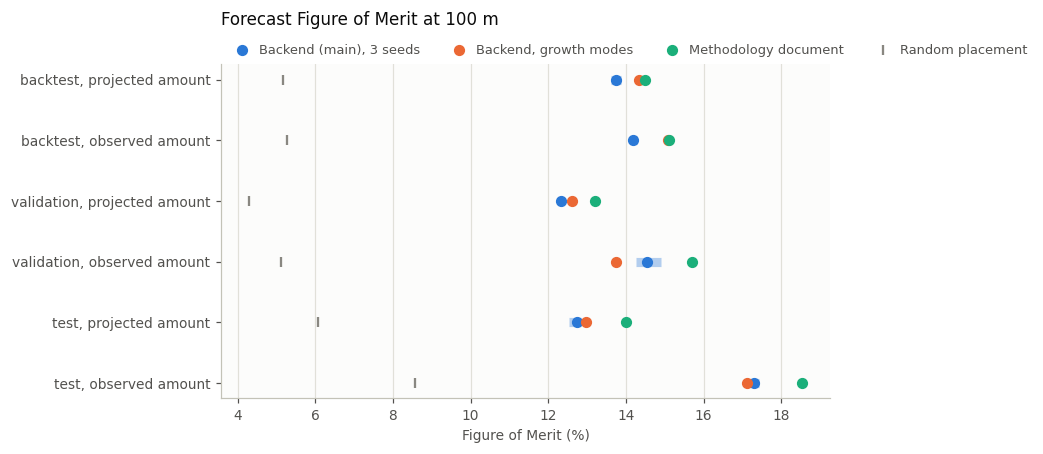

In [3]:
rows = list(tab.index)[::-1]
y = np.arange(len(rows))
fig, ax = plt.subplots(figsize=(8.5, 4.2))
lo = [backend.min()[r] for r in rows]; hi = [backend.max()[r] for r in rows]
ax.hlines(y, lo, hi, color=H.SERIES[0], linewidth=6, alpha=0.35, zorder=1)
ax.scatter(tab.loc[rows, "Backend, mean"], y, s=40, color=H.SERIES[0], zorder=3, label="Backend (main), 3 seeds")
ax.scatter(tab.loc[rows, "Growth modes"], y, s=40, color=H.SERIES[1], zorder=3, label="Backend, growth modes")
ax.scatter(tab.loc[rows, "Document"], y, s=40, color=H.SERIES[2], zorder=3, label="Methodology document")
ax.scatter(tab.loc[rows, "Random"], y, s=40, marker="|", color=H.MUTED, zorder=2, label="Random placement")
ax.set_yticks(y, [f"{w}, {a} amount" for w, a in rows])
ax.set_xlabel("Figure of Merit (%)", color=H.INK_2)
H.style_axes(ax)
ax.set_title("Forecast Figure of Merit at 100 m", loc="left", color=H.INK, fontsize=11, pad=26)
ax.legend(frameon=False, fontsize=8.5, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=4, labelcolor=H.INK_2,
          handletextpad=0.3, borderaxespad=0.2)
plt.tight_layout(); plt.show()

**Reading:**

* **The document's method scores highest in every window**, with both amounts: 13.2–14.5 % with the projected amount against 12.3–13.7 % for the backend (mean of seeds), and 15.1–18.5 % against 14.2–17.3 % with the observed amount.
* **The growth-mode option is no consistent gain:** better than the backend in the backtest window, worse in validation with the observed amount.
* **All methods beat random placement**, by 7–10 points.
* main's own `figure_of_merit` gives the same values (cell above), so these are the numbers the platform would report.

## 3 · Is the gain larger than the seed noise?

A gain counts only if it is larger than the spread from the random seed alone (Bouthillier et al. 2021). The backend's three seeds give that spread; the document's method was run with seed 42, so it is compared with the backend's seed-42 run.

In [4]:
b42 = base[(base.method == "backend") & (base.seed == 42)].set_index(["phase", "demand"])
doc = base[base.method == "document"].set_index(["phase", "demand"])
gain = pd.DataFrame({
    "Document − backend (FoM)": doc["FoM"] - b42["FoM"],
    "Backend seed range (FoM)": backend.max() - backend.min(),
}).reindex(tab.index)
C.save("04_document_gain.csv", gain)
gain.round(2)

Document − backend (FoM)  Backend seed range (FoM)
window     amount                                                       
backtest   projected                      0.62                      0.24
           observed                       0.83                      0.19
validation projected                      0.87                      0.09
           observed                       1.44                      0.65
test       projected                      1.21                      0.30
           observed                       1.26                      0.21

**Reading:** the document's method gains 0.6–1.4 points of Figure of Merit, 2–10 times the backend's spread across seeds (0.1–0.7 points). It is the only candidate here that beats the deployed method in every window. Over all of Guinea, in the test window with the observed amount, it has 57,000 more hits, 52,000 fewer misses and 58,000 fewer false alarms than the backend (32,000–59,000 more hits in the other windows): the gain is spread over many small changes next to existing patches. Why its two parts, the Expander sample and the neighbourhood predictor, help: notebook 05, section 9.

## 4 · Clouds and the 1,000-pixel rule on the backend

The two fixes applied alone to the backend's seed-42 run, on its own suitability maps.

In [5]:
fix = S[(S.method == "backend") & (S.seed == 42)].pivot_table(index=["phase", "demand"], columns="variant", values="FoM")
fix = fix[["as it runs", "no clouds", "1,000-pixel rule", "both"]].reindex(tab.index)
C.save("04_backend_fixes.csv", fix)
fix.round(2)

variant               as it runs  no clouds  1,000-pixel rule   both
window     amount                                                   
backtest   projected       13.86      13.86             13.86  13.86
           observed        14.29      14.29             14.29  14.29
validation projected       12.34      12.34             12.34  12.34
           observed        14.26      14.26             14.26  14.26
test       projected       12.80      12.80             12.80  12.80
           observed        17.28      17.28             17.27  17.27

**Reading:** neither fix changes the score by more than 0.01 points. Clouds cover 12 cells of Guinea in 2023 and none in the other years used here, and the transitions below 1,000 cells carry 0.2 % of the change. Both are still right to apply, for the reasons in section 1: a cloud is not a land cover, and a model trained on a few dozen cells is not reliable (Thanh Noi & Kappas 2018); they cost nothing in accuracy.

## 5 · The amount of change

How many cells the platform's projection changes, against the change that happened (cells inside Guinea, valid classes).

In [6]:
amt = b42.xs("projected", level="demand")[["predicted change (cells)", "observed change (cells)"]].reindex(WINDOWS)
amt["projected vs observed (%)"] = 100 * (amt["predicted change (cells)"] / amt["observed change (cells)"] - 1)
C.save("04_amount.csv", amt)
amt.round(1)

,predicted change (cells),observed change (cells),projected vs observed (%)
phase,,,
backtest,2132417,2612406,-18.4
validation,2213703,2692143,-17.8
test,2324032,3170045,-26.7


**Reading:** a forecast has two parts: how much land changes, and where. The platform projects how much with a trend fitted per transition on every interval since 2017, and in every window it projects 18–27 % fewer changed cells than Esri's next map shows. That part of the error does not depend on where change is placed, so every method scores higher with the observed amount. This is why methods are compared on placement with the observed amount, while users get the projected one. The trend is low because Esri's maps change 10–15 % of Guinea a year and a third of it goes back the next year (notebook 01): a trend cannot follow change that turns back. Other amount rules are tested in notebook 05, section 6.

## 6 · Server cost

Minutes and peak memory of each stage of the platform's run, on this device (seed 42, mean of the three windows). Peak memory is the whole process with its workers.

In [7]:
cost = D.stage_costs().groupby(["method", "stage"], sort=False)[["minutes", "peak_GB"]].mean()
total = D.stage_costs().groupby(["method", "phase"])["minutes"].sum().groupby("method").mean()
C.save("04_server_cost.csv", cost)
print("Total minutes per run:", total.round(1).to_dict())
cost.round(2)

Total minutes per run: {'backend': 16.0, 'document': 9.4, 'growth': 28.6}


minutes  peak_GB
method   stage                                 
backend  Training transitions     0.15     1.49
         Training                 5.53     3.71
         Suitability atlas        8.38     3.73
         Demand                   1.08     1.51
         Allocation               0.88     1.63
growth   Training transitions     0.16     1.44
         Training                10.09     3.71
         Suitability atlas       15.41     3.62
         Demand                   1.11     1.43
         Allocation               1.82     2.11
document Train and score          9.39     3.73

**Reading:**

* **The backend takes about 16 minutes and peaks at 3.7 GB** per run at 100 m: 5.5 min training, 8.4 min suitability maps, 2 min demand and allocation.
* **The growth-mode option nearly doubles the run** (68–73 models instead of 37–38), to about 29 minutes, at the same memory.
* **The document's method is quicker than the backend:** 9.4 min to train and score its 23 models, about 11 min with the same demand and allocation, at 3.7 GB. Fewer models outweigh the extra predictor.
* All stay well under the server's limit of about 10 GB; the platform's out-of-memory failures come from holding the 12 predictors in memory (5.3 GB, notebook 02), not from these stages.

## 7 · What this means

* **The deployed backend scores 12.3–13.9 %** as the platform runs it at 100 m, and 14.1–17.4 % with the observed amount; main's own validation reports the same numbers.
* **The methodology document's method beats it in every window,** by more than the seed noise, and runs faster. The backend does not run what the document describes: it uses neither the Expander logic with a neighbourhood predictor (Soares-Filho et al. 2002; Verburg et al. 2002) nor the 1,000-pixel rule, and it keeps clouds.
* **Clouds and the 1,000-pixel rule do not change the score** but are both supported by the literature; worth applying.
* **The projected amount is 18–27 % too low** in every window; with the observed amount every method scores 0.4–4.6 points higher.
* **Next, notebook 05:** the parts of the document's method one at a time, with three seeds, and the 250 m decisions re-tested at 100 m.

**Sources**

* Bouthillier, X. et al. (2021). Accounting for variance in machine learning benchmarks. *Proceedings of Machine Learning and Systems* 3, 747–769.
* Burnham, K.P., Anderson, D.R. (2002). *Model Selection and Multimodel Inference*, 2nd ed. Springer.
* Karra, K. et al. (2021). Global land use/land cover with Sentinel 2 and deep learning. *IGARSS 2021*, 4704–4707.
* Mas, J.-F. et al. (2014). Inductive pattern-based land use/cover change models: a comparison of four software packages. *Environmental Modelling & Software* 51, 94–111.
* Pontius, R.G. Jr. et al. (2008). Comparing the input, output, and validation maps for several models of land change. *Annals of Regional Science* 42, 11–37.
* Soares-Filho, B.S., Coutinho Cerqueira, G., Lopes Pennachin, C. (2002). DINAMICA — a stochastic cellular automata model designed to simulate the landscape dynamics in an Amazonian colonization frontier. *Ecological Modelling* 154, 217–235.
* Thanh Noi, P., Kappas, M. (2018). Comparison of Random Forest, k-Nearest Neighbor, and Support Vector Machine classifiers for land cover classification using Sentinel-2 imagery. *Sensors* 18(1), 18.
* Verburg, P.H. et al. (2002). Modeling the spatial dynamics of regional land use: the CLUE-S model. *Environmental Management* 30, 391–405.
* GEDH platform repository, `main` (6710b3d): `backend/landuse_api/tasks.py`, `landuse_tool/training.py`, `prediction.py`, `change_analysis.py`, `validation.py`; `Docs/Methodology_LandUse_Guinea.docx` (2026-09-27).